In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [12]:
df = pd.read_csv("/kaggle/input/datasets/uciml/iris/Iris.csv")

In [13]:
X = df.drop(columns=["Id", "Species"])
y = LabelEncoder().fit_transform(df["Species"])

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [16]:
class LinearSVM:
    """Multiclass linear SVM (hinge loss + L2) trained with: SGD (batch_size=1)"""

    def __init__(self, lr=0.01, epochs=100, batch_size=1, reg=0.001, random_state=42):
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.reg = reg
        self.rng = np.random.RandomState(random_state)

    def _grad(self, Xb, yb):
        n = Xb.shape[0]
        scores = Xb @ self.W + self.b
        correct = scores[np.arange(n), yb][:, None]
        margins = scores - correct + 1
        margins[np.arange(n), yb] = 0
        mask = (margins > 0).astype(float)
        mask[np.arange(n), yb] = -mask.sum(axis=1)
        dW = Xb.T @ mask / n + self.reg * self.W
        db = mask.sum(axis=0) / n
        return dW, db

    def _update(self, dW, db):
        self.W -= self.lr * dW
        self.b -= self.lr * db

    def fit(self, X, y):
        X = np.asarray(X); y = np.asarray(y)
        n, d = X.shape
        k = len(np.unique(y))
        self.W = self.rng.randn(d, k) * 0.01
        self.b = np.zeros(k)

        self.t = 0
        self.losses = []
        for epoch in range(self.epochs):
            idx = self.rng.permutation(n)
            for s in range(0, n, self.batch_size):
                batch = idx[s:s + self.batch_size]
                dW, db = self._grad(X[batch], y[batch])
                self.t += 1
                self._update(dW, db)
            sc = X @ self.W + self.b
            m = np.maximum(0, sc - sc[np.arange(n), y][:, None] + 1)
            m[np.arange(n), y] = 0
            self.losses.append(m.sum(axis=1).mean() + 0.5 * self.reg * np.sum(self.W ** 2))
        return self

    def predict(self, X):
        return np.argmax(np.asarray(X) @ self.W + self.b, axis=1)

In [17]:
model = LinearSVM()

In [18]:
model.fit(X_train, y_train)

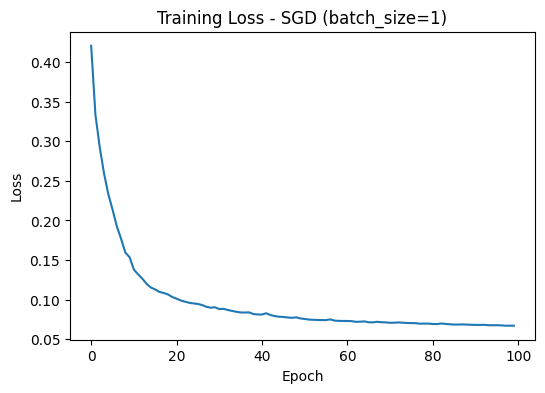

In [19]:
plt.figure(figsize=(6, 4))
plt.plot(model.losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss - SGD (batch_size=1)")
plt.show()

In [20]:
y_pred = model.predict(X_test)

In [21]:
print("SVM Results (SGD (batch_size=1))")
print("------------------------------")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="macro"))
print("Recall   :", recall_score(y_test, y_pred, average="macro"))
print("F1 Score :", f1_score(y_test, y_pred, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

SVM Results (SGD (batch_size=1))
------------------------------
Accuracy : 0.9666666666666667
Precision: 0.9696969696969697
Recall   : 0.9666666666666667
F1 Score : 0.9665831244778612

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



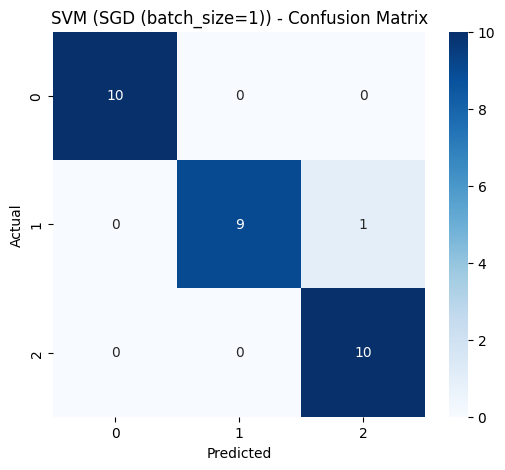

In [22]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM (SGD (batch_size=1)) - Confusion Matrix")
plt.show()